In [1]:
from pathlib import Path

# Works when the notebook is launched from either the repository root or notebooks/.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "ETTm2.csv"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

import pandas as pd
import torch
from IPython.display import display

df = pd.read_csv(DATA_PATH, parse_dates=["date"])

print("데이터 크기:", df.shape)
print("기간:", df["date"].min(), "~", df["date"].max())
print("전체 결측값 수:", df.isna().sum().sum())
print("중복 시각 수:", df["date"].duplicated().sum())
print("기록 간격별 개수:")
print(df["date"].diff().value_counts())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "사용 불가")

display(df.head())

데이터 크기: (69680, 8)
기간: 2016-07-01 00:00:00 ~ 2018-06-26 19:45:00
전체 결측값 수: 0
중복 시각 수: 0
기록 간격별 개수:
date
0 days 00:15:00    69679
Name: count, dtype: int64
GPU: NVIDIA GeForce RTX 4060


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,41.130001,12.481,36.535999,9.355,4.424,1.311,38.661999
1,2016-07-01 00:15:00,39.622002,11.309,35.543999,8.551,3.209,1.258,38.223000
2,2016-07-01 00:30:00,38.868000,10.555,34.365002,7.586,4.435,1.258,37.344002
3,2016-07-01 00:45:00,35.518002,9.214,32.569000,8.712,4.435,1.215,37.124001
4,2016-07-01 01:00:00,37.528000,10.136,33.936001,7.532,4.435,1.215,37.124001


In [2]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from IPython.display import display

# 1. 데이터를 시간순으로 정렬
df = pd.read_csv(DATA_PATH, parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)

feature_cols = ["HUFL", "HULL", "MUFL", "MULL", "LUFL", "LULL", "OT"]

# 2. 시간순으로 학습 70%, 검증 15%, 테스트 15% 분할
train_end = int(len(df) * 0.70)
val_end = train_end + int(len(df) * 0.15)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

split_info = pd.DataFrame([
    {
        "구간": name,
        "행 수": len(part),
        "시작 시각": part["date"].iloc[0],
        "종료 시각": part["date"].iloc[-1]
    }
    for name, part in [
        ("학습", train_df),
        ("검증", val_df),
        ("테스트", test_df)
    ]
])

print("데이터 분할 결과")
display(split_info)

# 3. 학습 데이터로만 스케일링 기준을 계산
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_df[feature_cols]).astype(np.float32)

# 4. 검증 데이터에는 학습 데이터에서 구한 기준을 그대로 적용
val_scaled = scaler.transform(val_df[feature_cols]).astype(np.float32)

# 테스트 데이터는 test_df에 원본 상태로 보관
# 최종 평가 단계에서 동일한 scaler로 변환하여 사용

# 5. 학습 데이터의 스케일링 결과 확인
scaling_check = pd.DataFrame({
    "변수": feature_cols,
    "변환 후 학습 평균": train_scaled.mean(axis=0),
    "변환 후 학습 표준편차": train_scaled.std(axis=0)
})

print("학습 데이터 스케일링 확인")
display(scaling_check.round(4))

print("학습 배열 크기:", train_scaled.shape)
print("검증 배열 크기:", val_scaled.shape)
print("테스트 데이터는 별도로 보관했으며, 아직 성능 평가는 하지 않았습니다.")

데이터 분할 결과


,구간,행 수,시작 시각,종료 시각
0,학습,48776,2016-07-01 00:00:00,2017-11-21 01:45:00
1,검증,10452,2017-11-21 02:00:00,2018-03-09 22:45:00
2,테스트,10452,2018-03-09 23:00:00,2018-06-26 19:45:00


학습 데이터 스케일링 확인


,변수,변환 후 학습 평균,변환 후 학습 표준편차
0,HUFL,0.0,1.0
1,HULL,-0.0,1.0
2,MUFL,0.0,1.0
3,MULL,0.0,1.0
4,LUFL,-0.0,1.0
5,LULL,0.0,1.0
6,OT,-0.0,1.0


학습 배열 크기: (48776, 7)
검증 배열 크기: (10452, 7)
테스트 데이터는 별도로 보관했으며, 아직 성능 평가는 하지 않았습니다.


In [3]:
input_len = 96
pred_len = 96
target_idx = feature_cols.index("OT")

# 과거 96시점의 7개 변수를 입력으로 사용
x_example = train_scaled[:input_len]

# 이어지는 미래 96시점의 OT만 정답으로 사용
y_example = train_scaled[input_len:input_len + pred_len, target_idx]

print("입력 X 크기:", x_example.shape)
print("정답 y 크기:", y_example.shape)

print("입력 기간:", train_df["date"].iloc[0], "~", train_df["date"].iloc[input_len - 1])
print("정답 기간:", train_df["date"].iloc[input_len], "~", train_df["date"].iloc[input_len + pred_len - 1])

입력 X 크기: (96, 7)
정답 y 크기: (96,)
입력 기간: 2016-07-01 00:00:00 ~ 2016-07-01 23:45:00
정답 기간: 2016-07-02 00:00:00 ~ 2016-07-02 23:45:00


In [4]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

SEEDS = [0, 1, 2]
PRED_LEN = 96
BATCH_SIZE = 64
MAX_INPUT_LEN = 288
TARGET_IDX = feature_cols.index("OT")

# 과거 입력을 참조할 수 있도록 연결
# 학습과 검증의 정답 구간은 아래에서 각각 제한
train_val_tensor = torch.from_numpy(
    np.concatenate([train_scaled, val_scaled], axis=0)
)


class WindowDataset(Dataset):
    def __init__(self, data, input_len, pred_len, target_start, target_end, target_idx):
        if target_start < input_len or target_end > len(data) or target_start + pred_len > target_end:
            raise ValueError("입력 길이 또는 정답 구간을 확인하세요.")

        self.data = data
        self.input_len = input_len
        self.pred_len = pred_len
        self.target_idx = target_idx

        # 정답 96개가 해당 구간 안에 모두 들어가는 시작점만 사용
        self.origins = range(target_start, target_end - pred_len + 1)

    def __len__(self):
        return len(self.origins)

    def __getitem__(self, idx):
        t = self.origins[idx]

        x = self.data[t - self.input_len:t]
        y = self.data[t:t + self.pred_len, self.target_idx]

        return x, y


def make_loaders(input_len=96, seed=0):
    train_dataset = WindowDataset(
        train_val_tensor, input_len, PRED_LEN,
        MAX_INPUT_LEN, len(train_scaled), TARGET_IDX
    )

    val_dataset = WindowDataset(
        train_val_tensor, input_len, PRED_LEN,
        len(train_scaled), len(train_val_tensor), TARGET_IDX
    )

    generator = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE,
        shuffle=True, generator=generator, num_workers=0
    )

    val_loader = DataLoader(
        val_dataset, batch_size=BATCH_SIZE,
        shuffle=False, num_workers=0
    )

    return train_loader, val_loader


# 구조 확인용이며, 실제 학습할 때는 시드별로 다시 생성
train_loader, val_loader = make_loaders(input_len=96, seed=SEEDS[0])

x_batch, y_batch = next(iter(train_loader))

print("학습 묶음 수:", len(train_loader.dataset))
print("검증 묶음 수:", len(val_loader.dataset))
print("입력 배치 크기:", tuple(x_batch.shape))
print("정답 배치 크기:", tuple(y_batch.shape))

학습 묶음 수: 48393
검증 묶음 수: 10357
입력 배치 크기: (64, 96, 7)
정답 배치 크기: (64, 96)


In [5]:
import torch
from torch import nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("사용 장치:", device)


class ForecastModel(nn.Module):
    def __init__(self, model_type, input_size=7, hidden_size=64, num_layers=1, pred_len=96):
        super().__init__()

        layer_types = {
            "RNN": nn.RNN,
            "LSTM": nn.LSTM,
            "GRU": nn.GRU
        }

        if model_type not in layer_types:
            raise ValueError("model_type은 RNN, LSTM, GRU 중 하나여야 합니다.")

        # 과거 데이터를 시간순으로 읽는 부분
        self.recurrent = layer_types[model_type](
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.0
        )

        # 과거에서 얻은 특징으로 미래 96개 값을 출력
        self.output_layer = nn.Linear(hidden_size, pred_len)

    def forward(self, x):
        outputs, _ = self.recurrent(x)

        # 과거 시점들을 모두 읽은 후의 마지막 상태
        last_state = outputs[:, -1, :]

        prediction = self.output_layer(last_state)
        return prediction


# 앞서 만든 실제 입력 배치로 구조 확인
x_check = x_batch.to(device)

for model_name in ["RNN", "LSTM", "GRU"]:
    torch.manual_seed(SEEDS[0])

    model = ForecastModel(
        model_type=model_name,
        input_size=len(feature_cols),
        hidden_size=64,
        num_layers=1,
        pred_len=PRED_LEN
    ).to(device)

    model.eval()

    with torch.no_grad():
        prediction = model(x_check)

    assert prediction.shape == y_batch.shape, "예측과 정답의 크기가 다릅니다."

    parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)

    print(f"{model_name}: 출력 {tuple(prediction.shape)}, 파라미터 {parameter_count:,}개")

사용 장치: cuda
RNN: 출력 (64, 96), 파라미터 10,912개
LSTM: 출력 (64, 96), 파라미터 24,928개
GRU: 출력 (64, 96), 파라미터 20,256개


In [6]:
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn

# 세 모델에 공통으로 적용할 설정
TRAIN_CONFIG = {
    "hidden_size": 64,
    "num_layers": 1,
    "lr": 0.001,
    "max_epochs": 30,
    "patience": 5,
}

def train_one_model(model_type, input_len=96, seed=0):
    # 각 실험의 난수 초기 상태 설정
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.backends.cudnn.benchmark = False

    # 실험마다 데이터로더, 모델, 옵티마이저를 새로 생성
    train_loader, val_loader = make_loaders(input_len, seed)

    config = {
        **TRAIN_CONFIG,
        "model_type": model_type,
        "input_len": input_len,
        "input_size": len(feature_cols),
        "pred_len": PRED_LEN,
        "batch_size": BATCH_SIZE,
        "seed": seed,
    }

    model = ForecastModel(
        model_type=model_type,
        input_size=config["input_size"],
        hidden_size=config["hidden_size"],
        num_layers=config["num_layers"],
        pred_len=config["pred_len"],
    ).to(device)

    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"])

    save_dir = RESULTS_DIR
    save_dir.mkdir(parents=True, exist_ok=True)
    run_name = f"{model_type}_input{input_len}_seed{seed}"
    checkpoint_path = save_dir / f"{run_name}.pt"
    history_path = save_dir / f"{run_name}_history.csv"

    history = []
    best_mse = float("inf")
    best_state = None
    no_improvement = 0
    run_start = time.perf_counter()

    for epoch in range(1, config["max_epochs"] + 1):
        epoch_start = time.perf_counter()

        # 1. 학습: 예측 → 오차 계산 → 가중치 수정
        model.train()
        train_error_sum = 0.0
        train_count = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad(set_to_none=True)
            prediction = model(x)
            loss = loss_fn(prediction, y)

            loss_value = loss.item()
            if not np.isfinite(loss_value):
                raise RuntimeError("학습 오차가 NaN 또는 inf입니다.")

            loss.backward()
            optimizer.step()

            # 마지막 작은 배치도 정확한 비중으로 반영
            train_error_sum += loss_value * y.numel()
            train_count += y.numel()

        train_mse = train_error_sum / train_count

        # 2. 검증: 가중치 수정 없이 MSE와 MAE 계산
        model.eval()
        squared_error_sum = 0.0
        absolute_error_sum = 0.0
        val_count = 0

        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                error = model(x) - y

                squared_error_sum += error.square().sum().item()
                absolute_error_sum += error.abs().sum().item()
                val_count += y.numel()

        val_mse = squared_error_sum / val_count
        val_mae = absolute_error_sum / val_count

        if not np.isfinite(val_mse) or not np.isfinite(val_mae):
            raise RuntimeError("검증 오차가 NaN 또는 inf입니다.")

        history.append({
            "epoch": epoch,
            "train_mse": train_mse,
            "val_mse": val_mse,
            "val_mae": val_mae,
            "seconds": time.perf_counter() - epoch_start,
        })

        # 3. 검증 MSE가 개선되면 해당 가중치 저장
        improved = val_mse < best_mse

        if improved:
            best_mse = val_mse
            no_improvement = 0
            best_state = {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            }

            torch.save({
                "model_state_dict": best_state,
                "config": config,
                "best_epoch": epoch,
                "val_mse": val_mse,
                "val_mae": val_mae,
                "metric_scale": "standardized",
                "feature_cols": list(feature_cols),
                "scaler_mean": scaler.mean_.tolist(),
                "scaler_scale": scaler.scale_.tolist(),
                "train_end": train_end,
                "val_end": val_end,
            }, checkpoint_path)
        else:
            no_improvement += 1

        pd.DataFrame(history).to_csv(history_path, index=False)

        mark = " ← 최저 기록 갱신" if improved else ""
        print(
            f"Epoch {epoch:02d} | "
            f"학습 MSE {train_mse:.5f} | "
            f"검증 MSE {val_mse:.5f} | "
            f"검증 MAE {val_mae:.5f} | "
            f"{history[-1]['seconds']:.1f}초{mark}",
            flush=True,
        )

        if no_improvement >= config["patience"]:
            print(f"검증 MSE가 {config['patience']}회 연속 개선되지 않아 종료합니다.")
            break

    # 마지막 epoch 대신 검증 성능이 가장 좋았던 가중치 복원
    model.load_state_dict(best_state)
    model.eval()

    print(f"\n총 소요 시간: {(time.perf_counter() - run_start) / 60:.1f}분")
    print(f"모델 저장 위치: {checkpoint_path.resolve()}")

    return model, pd.DataFrame(history)

Epoch 01 | 학습 MSE 0.20349 | 검증 MSE 0.37183 | 검증 MAE 0.49972 | 1.7초 ← 최저 기록 갱신
Epoch 02 | 학습 MSE 0.11385 | 검증 MSE 0.20424 | 검증 MAE 0.35651 | 1.5초 ← 최저 기록 갱신
Epoch 03 | 학습 MSE 0.08857 | 검증 MSE 0.26366 | 검증 MAE 0.39722 | 1.5초
Epoch 04 | 학습 MSE 0.07951 | 검증 MSE 0.23277 | 검증 MAE 0.36752 | 1.5초
Epoch 05 | 학습 MSE 0.07428 | 검증 MSE 0.18571 | 검증 MAE 0.32277 | 1.5초 ← 최저 기록 갱신
Epoch 06 | 학습 MSE 0.06828 | 검증 MSE 0.24128 | 검증 MAE 0.37909 | 1.5초
Epoch 07 | 학습 MSE 0.06313 | 검증 MSE 0.26561 | 검증 MAE 0.39008 | 1.5초
Epoch 08 | 학습 MSE 0.05768 | 검증 MSE 0.25059 | 검증 MAE 0.37848 | 1.5초
Epoch 09 | 학습 MSE 0.05467 | 검증 MSE 0.29501 | 검증 MAE 0.41193 | 1.5초
Epoch 10 | 학습 MSE 0.05095 | 검증 MSE 0.24899 | 검증 MAE 0.38029 | 1.6초
검증 MSE가 5회 연속 개선되지 않아 종료합니다.

총 소요 시간: 0.3분
모델 저장 위치: .../ettm2-oil-temperature-forecasting\results\LSTM_input96_seed0.pt

선택된 epoch: 5
검증 MSE: 0.18571
검증 MAE: 0.32277


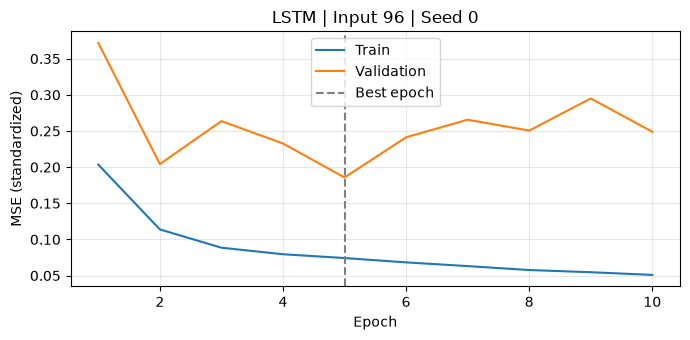

In [7]:
import matplotlib.pyplot as plt

lstm_model, lstm_history = train_one_model(
    model_type="LSTM",
    input_len=96,
    seed=SEEDS[0],  # 0
)

# 검증 MSE를 기준으로 선택한 epoch의 결과
best = lstm_history.loc[lstm_history["val_mse"].idxmin()]

print(f"\n선택된 epoch: {int(best['epoch'])}")
print(f"검증 MSE: {best['val_mse']:.5f}")
print(f"검증 MAE: {best['val_mae']:.5f}")

plt.figure(figsize=(7, 3.5))
plt.plot(lstm_history["epoch"], lstm_history["train_mse"], label="Train")
plt.plot(lstm_history["epoch"], lstm_history["val_mse"], label="Validation")
plt.axvline(best["epoch"], color="gray", linestyle="--", label="Best epoch")
plt.xlabel("Epoch")
plt.ylabel("MSE (standardized)")
plt.title("LSTM | Input 96 | Seed 0")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
from pathlib import Path
import pandas as pd
import torch
from IPython.display import display

save_dir = RESULTS_DIR
validation_rows = []

for model_name in ["RNN", "LSTM", "GRU"]:
    for seed in SEEDS:
        print(f"\n===== {model_name} | 입력 96 | 시드 {seed} =====")

        if model_name == "LSTM" and seed == 0:
            print("앞에서 완료한 LSTM·시드 0 결과를 사용합니다.")
        else:
            trained_model, history = train_one_model(
                model_type=model_name,
                input_len=96,
                seed=seed,
            )
            del trained_model

        # 각 실행에서 검증 MSE가 가장 낮았던 모델의 기록 읽기
        checkpoint_path = save_dir / f"{model_name}_input96_seed{seed}.pt"
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True,
        )

        validation_rows.append({
            "model": model_name,
            "seed": seed,
            "best_epoch": checkpoint["best_epoch"],
            "val_mse": checkpoint["val_mse"],
            "val_mae": checkpoint["val_mae"],
        })

# 9회 실행 각각의 결과
validation_results = pd.DataFrame(validation_rows)

# 모델별로 세 시드의 평균과 표준편차 계산
comparison = (
    validation_results.groupby("model")
    .agg(
        mse_mean=("val_mse", "mean"),
        mse_std=("val_mse", "std"),
        mae_mean=("val_mae", "mean"),
        mae_std=("val_mae", "std"),
    )
    .sort_values("mse_mean")
)

validation_results.to_csv(
    save_dir / "base_validation_runs.csv", index=False
)
comparison.to_csv(save_dir / "base_validation_summary.csv")

print("\n실행별 검증 결과 — 스케일링된 OT 기준")
display(validation_results.round(5))

print("\n모델별 검증 결과 — 평균 MSE가 낮은 순서")
display(comparison.round(5))


===== RNN | 입력 96 | 시드 0 =====
Epoch 01 | 학습 MSE 0.21179 | 검증 MSE 0.36541 | 검증 MAE 0.50537 | 1.4초 ← 최저 기록 갱신
Epoch 02 | 학습 MSE 0.18095 | 검증 MSE 0.25782 | 검증 MAE 0.40412 | 1.5초 ← 최저 기록 갱신
Epoch 03 | 학습 MSE 0.17267 | 검증 MSE 0.28792 | 검증 MAE 0.41950 | 1.5초
Epoch 04 | 학습 MSE 0.18019 | 검증 MSE 0.35760 | 검증 MAE 0.48372 | 1.5초
Epoch 05 | 학습 MSE 0.18319 | 검증 MSE 0.34695 | 검증 MAE 0.47536 | 1.4초
Epoch 06 | 학습 MSE 0.16845 | 검증 MSE 0.29445 | 검증 MAE 0.42935 | 1.5초
Epoch 07 | 학습 MSE 0.16109 | 검증 MSE 0.46145 | 검증 MAE 0.55747 | 1.4초
검증 MSE가 5회 연속 개선되지 않아 종료합니다.

총 소요 시간: 0.2분
모델 저장 위치: .../ettm2-oil-temperature-forecasting\results\RNN_input96_seed0.pt

===== RNN | 입력 96 | 시드 1 =====
Epoch 01 | 학습 MSE 0.21902 | 검증 MSE 0.35203 | 검증 MAE 0.48575 | 1.5초 ← 최저 기록 갱신
Epoch 02 | 학습 MSE 0.17298 | 검증 MSE 0.25600 | 검증 MAE 0.40356 | 1.5초 ← 최저 기록 갱신
Epoch 03 | 학습 MSE 0.16295 | 검증 MSE 0.34907 | 검증 MAE 0.48795 | 1.5초
Epoch 04 | 학습 MSE 0.17548 | 검증 MSE 0.35493 | 검증 MAE 0.47314 | 1.4초
Epoch 05 | 학습 MSE 0.17703 | 검증 MSE

,model,seed,best_epoch,val_mse,val_mae
0,RNN,0,2,0.25782,0.40412
1,RNN,1,7,0.20569,0.35897
2,RNN,2,11,0.21180,0.36108
3,LSTM,0,5,0.18571,0.32277
4,LSTM,1,6,0.19887,0.34150
5,LSTM,2,6,0.15230,0.30527
6,GRU,0,6,0.13446,0.27734
7,GRU,1,7,0.15310,0.28606
8,GRU,2,8,0.15606,0.29801



모델별 검증 결과 — 평균 MSE가 낮은 순서


,mse_mean,mse_std,mae_mean,mae_std
model,,,,
GRU,0.14787,0.01171,0.28713,0.01038
LSTM,0.17896,0.02401,0.32318,0.01812
RNN,0.22510,0.02850,0.37472,0.02548


In [9]:
from pathlib import Path
import pandas as pd
import torch
from IPython.display import display

ABLATION_MODEL = "GRU"
INPUT_LENGTHS = [96, 192, 288]

save_dir = RESULTS_DIR
ablation_rows = []

for input_len in INPUT_LENGTHS:
    for seed in SEEDS:
        print(
            f"\n===== {ABLATION_MODEL} | "
            f"입력 {input_len} ({input_len // 4}시간) | 시드 {seed} ====="
        )

        if input_len == 96:
            print("앞에서 완료한 GRU·입력 96 결과를 사용합니다.")
        else:
            trained_model, history = train_one_model(
                model_type=ABLATION_MODEL,
                input_len=input_len,
                seed=seed,
            )
            del trained_model

        # 해당 실행에서 검증 MSE가 가장 낮았던 모델의 기록
        checkpoint_path = (
            save_dir / f"{ABLATION_MODEL}_input{input_len}_seed{seed}.pt"
        )
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True,
        )

        ablation_rows.append({
            "model": ABLATION_MODEL,
            "input_len": input_len,
            "seed": seed,
            "best_epoch": checkpoint["best_epoch"],
            "val_mse": checkpoint["val_mse"],
            "val_mae": checkpoint["val_mae"],
        })

# 입력 길이별 3회 실행 결과
ablation_results = pd.DataFrame(ablation_rows)

# 입력 길이가 늘어날 때의 변화를 보기 위해 길이 순서로 정렬
ablation_comparison = (
    ablation_results.groupby("input_len")
    .agg(
        mse_mean=("val_mse", "mean"),
        mse_std=("val_mse", "std"),
        mae_mean=("val_mae", "mean"),
        mae_std=("val_mae", "std"),
    )
    .sort_index()
)

ablation_results.to_csv(
    save_dir / f"{ABLATION_MODEL}_ablation_validation_runs.csv",
    index=False,
)
ablation_comparison.to_csv(
    save_dir / f"{ABLATION_MODEL}_ablation_validation_summary.csv"
)

print("\n실행별 검증 결과 — 스케일링된 OT 기준")
display(ablation_results.round(5))

print("\n입력 길이별 검증 결과 — 평균과 표준편차")
display(ablation_comparison.round(5))


===== GRU | 입력 96 (24시간) | 시드 0 =====
앞에서 완료한 GRU·입력 96 결과를 사용합니다.

===== GRU | 입력 96 (24시간) | 시드 1 =====
앞에서 완료한 GRU·입력 96 결과를 사용합니다.

===== GRU | 입력 96 (24시간) | 시드 2 =====
앞에서 완료한 GRU·입력 96 결과를 사용합니다.

===== GRU | 입력 192 (48시간) | 시드 0 =====
Epoch 01 | 학습 MSE 0.19025 | 검증 MSE 0.17868 | 검증 MAE 0.34573 | 1.6초 ← 최저 기록 갱신
Epoch 02 | 학습 MSE 0.09547 | 검증 MSE 0.16779 | 검증 MAE 0.31946 | 1.6초 ← 최저 기록 갱신
Epoch 03 | 학습 MSE 0.07983 | 검증 MSE 0.16478 | 검증 MAE 0.31070 | 1.7초 ← 최저 기록 갱신
Epoch 04 | 학습 MSE 0.07054 | 검증 MSE 0.23845 | 검증 MAE 0.37300 | 1.6초
Epoch 05 | 학습 MSE 0.06196 | 검증 MSE 0.33025 | 검증 MAE 0.43795 | 1.7초
Epoch 06 | 학습 MSE 0.05500 | 검증 MSE 0.28537 | 검증 MAE 0.40554 | 1.7초
Epoch 07 | 학습 MSE 0.04893 | 검증 MSE 0.33732 | 검증 MAE 0.45112 | 1.7초
Epoch 08 | 학습 MSE 0.04349 | 검증 MSE 0.28464 | 검증 MAE 0.40047 | 1.6초
검증 MSE가 5회 연속 개선되지 않아 종료합니다.

총 소요 시간: 0.2분
모델 저장 위치: .../ettm2-oil-temperature-forecasting\results\GRU_input192_seed0.pt

===== GRU | 입력 192 (48시간) | 시드 1 =====
Epoch 01 | 학습 MSE 0.18552

,model,input_len,seed,best_epoch,val_mse,val_mae
0,GRU,96,0,6,0.13446,0.27734
1,GRU,96,1,7,0.15310,0.28606
2,GRU,96,2,8,0.15606,0.29801
3,GRU,192,0,3,0.16478,0.31070
4,GRU,192,1,3,0.13819,0.28943
5,GRU,192,2,2,0.15801,0.31320
6,GRU,288,0,3,0.13912,0.28060
7,GRU,288,1,3,0.14551,0.29743
8,GRU,288,2,2,0.15122,0.30500



입력 길이별 검증 결과 — 평균과 표준편차


,mse_mean,mse_std,mae_mean,mae_std
input_len,,,,
96,0.14787,0.01171,0.28713,0.01038
192,0.15366,0.01382,0.30444,0.01306
288,0.14529,0.00605,0.29435,0.01249


In [10]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from IPython.display import display

# 테스트 결과를 보기 전에 검증 결과로 확정한 설정
FINAL_MODEL = "GRU"
FINAL_INPUT_LEN = 288

save_dir = RESULTS_DIR
prediction_dir = save_dir / "test_predictions"
prediction_dir.mkdir(parents=True, exist_ok=True)

selection = {
    "model": FINAL_MODEL,
    "input_len": FINAL_INPUT_LEN,
    "pred_len": PRED_LEN,
    "selection_metric": "mean validation MSE",
    "seeds": SEEDS,
}
(save_dir / "selection_before_test.json").write_text(
    json.dumps(selection, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# 학습 데이터에 맞춰둔 scaler로 테스트 데이터도 변환
test_scaled = scaler.transform(
    test_df[feature_cols]
).astype(np.float32)

# 테스트 시작 직전의 과거 관측값도 입력에 사용할 수 있도록 연결
all_scaled_tensor = torch.cat(
    [train_val_tensor, torch.from_numpy(test_scaled)], dim=0
)

def evaluate_test(checkpoint_path):
    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=True
    )
    config = checkpoint["config"]

    # 정답 y는 전부 테스트 구간 안에 위치
    test_dataset = WindowDataset(
        data=all_scaled_tensor,
        input_len=config["input_len"],
        pred_len=config["pred_len"],
        target_start=val_end,
        target_end=len(df),
        target_idx=TARGET_IDX,
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )

    model = ForecastModel(
        model_type=config["model_type"],
        input_size=config["input_size"],
        hidden_size=config["hidden_size"],
        num_layers=config["num_layers"],
        pred_len=config["pred_len"],
    ).to(device)

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    predictions = []
    targets = []

    # 저장된 가중치로 예측
    with torch.no_grad():
        for x, y in test_loader:
            prediction = model(x.to(device))
            predictions.append(prediction.cpu().numpy())
            targets.append(y.numpy())

    predictions = np.concatenate(predictions).astype(np.float64)
    targets = np.concatenate(targets).astype(np.float64)

    # 표준화된 OT를 원래 값으로 복원
    ot_mean = checkpoint["scaler_mean"][TARGET_IDX]
    ot_scale = checkpoint["scaler_scale"][TARGET_IDX]
    predictions = predictions * ot_scale + ot_mean
    targets = targets * ot_scale + ot_mean

    # 모든 예측 출발 시점 × 미래 96개 시점의 오차를 평균
    error = predictions - targets
    test_mse = float(np.mean(error ** 2))
    test_mae = float(np.mean(np.abs(error)))

    # 이후 그래프 작성에 사용할 예측값과 시각도 저장
    origin_dates = test_df["date"].iloc[
        :len(test_dataset)
    ].to_numpy(dtype="datetime64[ns]")

    np.savez_compressed(
        prediction_dir / f"{checkpoint_path.stem}.npz",
        y_pred=predictions,
        y_true=targets,
        origin_dates=origin_dates,
    )

    return {
        "model": config["model_type"],
        "input_len": config["input_len"],
        "seed": config["seed"],
        "test_mse": test_mse,
        "test_mae": test_mae,
    }

In [11]:
# 중복 없이 평가할 5가지 조건
test_conditions = [
    ("RNN", 96),
    ("LSTM", 96),
    ("GRU", 96),
    ("GRU", 192),
    ("GRU", 288),
]

test_rows = []

for model_name, input_len in test_conditions:
    for seed in SEEDS:
        checkpoint_path = (
            save_dir / f"{model_name}_input{input_len}_seed{seed}.pt"
        )
        result = evaluate_test(checkpoint_path)
        test_rows.append(result)

        print(
            f"{model_name} | 입력 {input_len} | 시드 {seed} | "
            f"테스트 MSE {result['test_mse']:.5f} | "
            f"테스트 MAE {result['test_mae']:.5f}"
        )

test_results = pd.DataFrame(test_rows)

# 시드별 성능을 먼저 계산한 후, 세 결과의 평균과 표준편차 산출
test_summary = (
    test_results.groupby(["model", "input_len"])
    .agg(
        mse_mean=("test_mse", "mean"),
        mse_std=("test_mse", "std"),
        mae_mean=("test_mae", "mean"),
        mae_std=("test_mae", "std"),
    )
    .reset_index()
)

# 기본 모델 비교는 입력 96으로 통일
base_test_summary = (
    test_summary[test_summary["input_len"] == 96]
    .drop(columns="input_len")
    .set_index("model")
    .reindex(["RNN", "LSTM", "GRU"])
)

# GRU의 입력 길이 비교
ablation_test_summary = (
    test_summary[test_summary["model"] == FINAL_MODEL]
    .drop(columns="model")
    .set_index("input_len")
    .sort_index()
)

test_results.to_csv(save_dir / "test_runs.csv", index=False)
base_test_summary.to_csv(save_dir / "base_test_summary.csv")
ablation_test_summary.to_csv(
    save_dir / "GRU_ablation_test_summary.csv"
)

print("\n기본 모델 비교 — 원래 OT 값 기준")
display(base_test_summary.round(5))

print("\nGRU 입력 길이 비교 — 원래 OT 값 기준")
display(ablation_test_summary.round(5))

print(
    f"\n검증 결과로 선택한 최종 설정: "
    f"{FINAL_MODEL}, 입력 {FINAL_INPUT_LEN}개"
)

RNN | 입력 96 | 시드 0 | 테스트 MSE 33.96988 | 테스트 MAE 4.63698
RNN | 입력 96 | 시드 1 | 테스트 MSE 36.08517 | 테스트 MAE 4.67974
RNN | 입력 96 | 시드 2 | 테스트 MSE 18.51091 | 테스트 MAE 3.20043
LSTM | 입력 96 | 시드 0 | 테스트 MSE 22.67452 | 테스트 MAE 3.46030
LSTM | 입력 96 | 시드 1 | 테스트 MSE 20.21073 | 테스트 MAE 3.24366
LSTM | 입력 96 | 시드 2 | 테스트 MSE 20.33074 | 테스트 MAE 3.23888
GRU | 입력 96 | 시드 0 | 테스트 MSE 21.41452 | 테스트 MAE 3.20664
GRU | 입력 96 | 시드 1 | 테스트 MSE 24.49452 | 테스트 MAE 3.48275
GRU | 입력 96 | 시드 2 | 테스트 MSE 19.30264 | 테스트 MAE 3.13346
GRU | 입력 192 | 시드 0 | 테스트 MSE 18.78144 | 테스트 MAE 3.05785
GRU | 입력 192 | 시드 1 | 테스트 MSE 17.46980 | 테스트 MAE 3.05008
GRU | 입력 192 | 시드 2 | 테스트 MSE 17.72010 | 테스트 MAE 3.05370
GRU | 입력 288 | 시드 0 | 테스트 MSE 18.32785 | 테스트 MAE 3.02809
GRU | 입력 288 | 시드 1 | 테스트 MSE 16.55817 | 테스트 MAE 2.94033
GRU | 입력 288 | 시드 2 | 테스트 MSE 16.78203 | 테스트 MAE 2.93244

기본 모델 비교 — 원래 OT 값 기준


,mse_mean,mse_std,mae_mean,mae_std
model,,,,
RNN,29.52199,9.59434,4.17238,0.84201
LSTM,21.07200,1.38912,3.31428,0.12648
GRU,21.73723,2.61094,3.27428,0.18421



GRU 입력 길이 비교 — 원래 OT 값 기준


,mse_mean,mse_std,mae_mean,mae_std
input_len,,,,
96,21.73723,2.61094,3.27428,0.18421
192,17.99044,0.69636,3.05388,0.00389
288,17.22268,0.96363,2.96695,0.05309



검증 결과로 선택한 최종 설정: GRU, 입력 288개


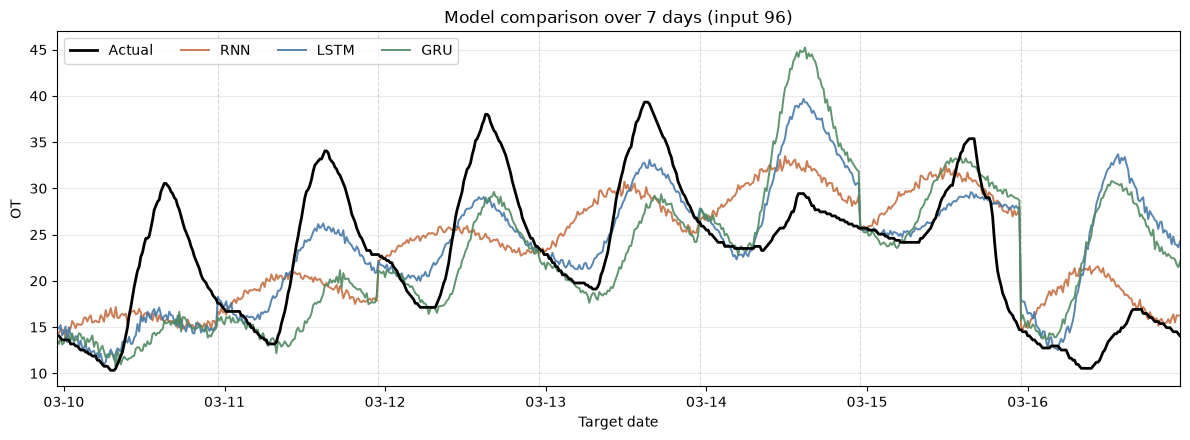

공통 조건: 입력 96, 예측 96, seed 0
표시 기간: 2018-03-09 23:00:00 ~ 2018-03-16 22:45:00
그래프 저장 위치: .../ettm2-oil-temperature-forecasting\results\figures\base_models_input96_7days.png
그래프 데이터 저장 위치: .../ettm2-oil-temperature-forecasting\results\figures\base_models_input96_7days.csv


In [14]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

result_dir = RESULTS_DIR
prediction_dir = result_dir / "test_predictions"
figure_dir = result_dir / "figures"

MODEL_NAMES = ["RNN", "LSTM", "GRU"]
INPUT_LEN = 96
PRED_LEN = 96
PLOT_SEED = 0
N_DAYS = 7

# 15분 간격의 예측 출발점 중 하루 간격으로 선택
day_indices = np.arange(N_DAYS) * PRED_LEN

actual = None
day_starts = None
predictions = {}

for model_name in MODEL_NAMES:
    prediction_path = (
        prediction_dir
        / f"{model_name}_input{INPUT_LEN}_seed{PLOT_SEED}.npz"
    )

    if not prediction_path.exists():
        raise FileNotFoundError(
            f"저장된 예측 파일이 없습니다: {prediction_path.resolve()}\n"
            "프로젝트 폴더에서 노트북을 실행하고 있는지 확인하세요."
        )

    # 실제값과 예측값은 이미 원래 OT 척도입니다.
    with np.load(prediction_path, allow_pickle=False) as saved:
        if len(saved["origin_dates"]) <= day_indices[-1]:
            raise ValueError(f"{model_name}: 7일을 표시할 자료가 부족합니다.")

        current_actual = saved["y_true"][day_indices].copy()
        current_prediction = saved["y_pred"][day_indices].copy()
        current_starts = saved["origin_dates"][day_indices].copy()

    expected_shape = (N_DAYS, PRED_LEN)
    if (
        current_actual.shape != expected_shape
        or current_prediction.shape != expected_shape
    ):
        raise ValueError(f"{model_name}: 예측 길이가 96개인지 확인하세요.")

    if actual is None:
        actual = current_actual
        day_starts = current_starts
    elif (
        not np.array_equal(day_starts, current_starts)
        or not np.allclose(actual, current_actual)
    ):
        raise ValueError("세 모델의 예측 대상 기간과 실제값이 다릅니다.")

    predictions[model_name] = current_prediction

target_times = pd.date_range(
    start=pd.Timestamp(day_starts[0]),
    periods=N_DAYS * PRED_LEN,
    freq="15min",
)

if not np.array_equal(target_times[::PRED_LEN].to_numpy(), day_starts):
    raise ValueError("예측 출발점이 하루 간격으로 이어지지 않습니다.")

plot_data = pd.DataFrame({
    "date": target_times,
    "Actual": actual.reshape(-1),
    **{
        model_name: predictions[model_name].reshape(-1)
        for model_name in MODEL_NAMES
    },
})

colors = {
    "RNN": "#C66F42",
    "LSTM": "#4679A8",
    "GRU": "#508A61",
}

fig, ax = plt.subplots(figsize=(12, 4.5))

ax.plot(
    plot_data["date"], plot_data["Actual"],
    color="black", linewidth=2, label="Actual", zorder=3,
)

# 7일의 예측값을 시간순으로 연결
for model_name in MODEL_NAMES:
    ax.plot(
        plot_data["date"], plot_data[model_name],
        color=colors[model_name],
        linewidth=1.4,
        alpha=0.9,
        label=model_name,
        zorder=2,
    )

# 새로운 하루 예측이 시작되는 위치
for boundary in day_starts[1:]:
    ax.axvline(
        pd.Timestamp(boundary),
        color="gray", linestyle="--",
        linewidth=0.8, alpha=0.3, zorder=1,
    )

ax.set_title("Model comparison over 7 days (input 96)")
ax.set_xlabel("Target date")
ax.set_ylabel("OT")
ax.set_xlim(target_times[0], target_times[-1])
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax.legend(ncol=4, loc="upper left")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "base_models_input96_7days.png"
csv_path = figure_dir / "base_models_input96_7days.csv"

fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plot_data.to_csv(csv_path, index=False, encoding="utf-8-sig")
plt.show()
plt.close(fig)

print(f"공통 조건: 입력 {INPUT_LEN}, 예측 {PRED_LEN}, seed {PLOT_SEED}")
print(f"표시 기간: {target_times[0]} ~ {target_times[-1]}")
print(f"그래프 저장 위치: {figure_path.resolve()}")
print(f"그래프 데이터 저장 위치: {csv_path.resolve()}")